In [1]:
import torch
import os
import monai.transforms as mt
import monai.data as md
import scipy.io as sio
import numpy as np
from liutuo_utils import compare_3d_jet,compare_3d,donkey_noise_like
import matplotlib.pyplot as plt
import pandas as pd
device_id =2

# 设置 PyTorch 的默认 CUDA 设备
torch.cuda.set_device(device_id)

# 确认当前默认 CUDA 设备
current_device = torch.cuda.current_device()
print(f"Switched to CUDA device: {current_device}")

/home/data/liutuo/.conda/envs/chouchou/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Switched to CUDA device: 2


In [2]:
from transformers import AutoProcessor, AutoModel

# 使用本地路径加载处理器和模型
local_model_path = "/home/data/liutuo/code/BiomedCLIP"

processor = AutoProcessor.from_pretrained(local_model_path, trust_remote_code=True)
model = AutoModel.from_pretrained(local_model_path, trust_remote_code=True)

In [3]:
from transformers import AutoProcessor, AutoModel
import torch
# 使用本地路径加载处理器和模型
local_model_path = "/home/data/liutuo/code/BiomedCLIP"
processor = AutoProcessor.from_pretrained(local_model_path, trust_remote_code=True)
model = AutoModel.from_pretrained(local_model_path, trust_remote_code=True)

# 将模型转移到设备
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
model.to(device)
model.eval()
context_length = 256

# modal_information = [
#     'T1-weighted imaging is an MRI technique that emphasizes tissues with lower water content. In T1-weighted images, bright areas represent fatty tissues, while dark areas indicate tissues with higher water content, such as fluids or edema.',
#     'PET (Positron Emission Tomography) visualizes metabolic processes using FDG (Fluorodeoxyglucose) as the radioactive tracer. Bright areas indicate high glucose uptake, like active brain regions or tumors, while dark areas show lower activity. PET pixel values represent tracer concentration, with higher values indicating greater metabolic activity.',
#     'CT (Computed Tomography) visualizes internal structures using X-rays. Bright areas (high density) represent dense tissues like bone, while dark areas (low density) indicate less dense tissues, such as air or fat. CT density values correlate with tissue composition, while PET density values reflect metabolic activity, with high values indicating increased glucose uptake.'
# ]

modal_information = [
    'T1-weighted MRI highlights tissues with low water content. Bright areas represent fatty tissues like brain white matter or subcutaneous fat. Dark areas indicate high water content tissues such as fluids, edema, or cerebrospinal fluid. This contrast helps to differentiate between various soft tissues based on their water content and composition, useful for detecting lesions or structural abnormalities.',
    
    'PET (Positron Emission Tomography) utilizes FDG (Fluorodeoxyglucose) as a radioactive tracer to visualize metabolic activity. Areas with high glucose uptake appear bright on PET images, indicating regions of high metabolic activity such as active brain regions, tumors, or inflamed tissues. Conversely, areas with low glucose uptake are darker. This imaging is crucial for evaluating tumor activity, brain function, and other metabolic processes by measuring tracer concentration.',
    
    'CT (Computed Tomography) uses X-rays to produce detailed images of internal body structures. Dense tissues like bone appear bright due to high X-ray absorption, while less dense tissues like air or fat appear dark. CT images are crucial for evaluating anatomical structures, diagnosing fractures, tumors, and internal bleeding. Unlike PET, which shows metabolic activity, CT primarily provides structural and density information.'
]
# 使用 tokenizer 进行文本处理
tokenizer = processor.tokenizer
inputs = tokenizer(modal_information, padding=True, truncation=True, return_tensors="pt", max_length=context_length)
texts = inputs['input_ids'].to(device)

# 计算文本嵌入特征
with torch.no_grad():
    text_features = model.get_text_features(texts)  # Replace `get_text_features` with the correct method
    print(text_features.shape, text_features.dtype)  # 打印嵌入特征的形状和数据类型


torch.Size([3, 512]) torch.float32


In [4]:
import os
import pandas as pd
import torch
from transformers import AutoProcessor, AutoModel
import scipy.io as sio

# 读取CSV文件并创建Subject到Description和Group的映射
label_path1 = "/home/data/liutuo/code/liutuo_data/ADNI1+2_baseline/ADNI1_imdb_with_meta_description.csv"
label_path2 = "/home/data/liutuo/code/liutuo_data/ADNI1+2_baseline/ADNI2_imdb_with_meta_description.csv"

label1 = pd.read_csv(label_path1)
label2 = pd.read_csv(label_path2)

label1_dict = dict(zip(label1["Subject"], label1["Group"]))
label2_dict = dict(zip(label2["Subject"], label2["Group"]))

label1_desc_dict = dict(zip(label1["Subject"], label1["description"]))
label2_desc_dict = dict(zip(label2["Subject"], label2["description"]))

# 使用本地路径加载处理器和模型
local_model_path = "/home/data/liutuo/code/BiomedCLIP"
processor = AutoProcessor.from_pretrained(local_model_path, trust_remote_code=True)
model = AutoModel.from_pretrained(local_model_path, trust_remote_code=True)

device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
model.to(device)
model.eval()

# 定义函数以读取.mat文件
def mat_load(mat_file_dir):
    mat = sio.loadmat(mat_file_dir)
    image = mat["IMG"]
    return image

# 获取路径中的数据列表
def get_data_list_from_path(path):
    data_list = [os.path.join(path, data) for data in os.listdir(path)]
    return data_list

# 获取路径中的数据并创建映射
def get_data_from_path(path, label_dict):
    data_all = []
    for data in os.listdir(path):
        image = os.path.join(path, data)
        name = data[:-4]
        try:
            label = label_dict[name]
        except KeyError:
            continue
        data_all.append({"image": image, "name": name, "label": label})
    return data_all

# 获取配对数据并附加Description
def get_data_from_path_paired_with_description(path, label_dict, label_desc_dict, mri_name_image_dict):
    data_all = []
    for data in os.listdir(path):
        pet = os.path.join(path, data)
        name = data[:-4]
        try:
            mri = mri_name_image_dict[name]
            label = label_dict[name]
            description = label_desc_dict[name]
        except KeyError:
            continue
        data_all.append({
            "pet": pet,
            "mri": mri,
            "name": name,
            "label": label,
            "description": description,
        })
    return data_all

# 设置路径
mri_path = "/home/data/liutuo/code/liutuo_data/ADNI1+2_baseline/MRI"
pet_path = "/home/data/liutuo/code/liutuo_data/ADNI1+2_baseline/PET"

# 获取MRI数据并创建映射
data_all = get_data_from_path(mri_path, label1_dict)
data_all_adni2 = get_data_from_path(mri_path, label2_dict)

mri_name_image_dict = dict(zip([data["name"] for data in data_all],
                               [data["image"] for data in data_all]))
mri_name_image_dict_adni2 = dict(zip([data["name"] for data in data_all_adni2],
                                     [data["image"] for data in data_all_adni2]))

# 获取配对数据并附加Description
paired_all_with_desc1 = get_data_from_path_paired_with_description(pet_path, label1_dict, label1_desc_dict, mri_name_image_dict)
paired_all_with_desc2 = get_data_from_path_paired_with_description(pet_path, label2_dict, label2_desc_dict, mri_name_image_dict_adni2)

# 合并两个数据集
paired_all_with_desc = paired_all_with_desc1 + paired_all_with_desc2

# 将Description转化为BiomedCLIP嵌入
modal_information = [data["description"] for data in paired_all_with_desc]
text_inputs = processor.tokenizer(modal_information, padding=True, truncation=True, return_tensors="pt", max_length=256).to(device)

with torch.no_grad():
    desc_text_features = model.get_text_features(text_inputs['input_ids'])  # 使用实际的特征提取方法
    print(desc_text_features.shape, desc_text_features.dtype)


torch.Size([1129, 512]) torch.float32


In [5]:
print(paired_all_with_desc)

[{'pet': '/home/data/liutuo/code/liutuo_data/ADNI1+2_baseline/PET/033_S_1281.mat', 'mri': '/home/data/liutuo/code/liutuo_data/ADNI1+2_baseline/MRI/033_S_1281.mat', 'name': '033_S_1281', 'label': 'AD', 'description': 'Subject is a 78-year-old female with a weight of 69.9 kg. The global Clinical Dementia Rating (CDR) score, which assesses dementia severity (0: no dementia to 3: severe dementia), is 1.0. The Mini-Mental State Examination (MMSE) score, assessing cognitive function (0: severe impairment to 30: normal), is 24.0. The Geriatric Depression Scale (GDS) score, screening depression (0: no depression to 15: severe depression), is 5.0. The Functional Activities Questionnaire (FAQ) score, assessing daily activity impairment (0: no impairment to 30: severe impairment), is 22.0.'}, {'pet': '/home/data/liutuo/code/liutuo_data/ADNI1+2_baseline/PET/131_S_0409.mat', 'mri': '/home/data/liutuo/code/liutuo_data/ADNI1+2_baseline/MRI/131_S_0409.mat', 'name': '131_S_0409', 'label': 'MCI', 'descr

In [6]:
c_mri= text_features[0].unsqueeze(0).to(dtype=torch.float32).to(device)
c_pet= text_features[1].unsqueeze(0).to(dtype=torch.float32).to(device)
c_ct= text_features[2].unsqueeze(0).to(dtype=torch.float32).to(device)
print(c_ct.shape)

torch.Size([1, 512])


In [7]:
# 修改后的函数，用于获取配对数据并附加Description和text_mri, text_pet
def get_data_from_path_paired_with_description(path, label_dict, label_desc_dict, mri_name_image_dict):
    data_all = []
    for i, data in enumerate(os.listdir(path)):
        pet = os.path.join(path, data)
        name = data[:-4]
        try:
            mri = mri_name_image_dict[name]
            label = label_dict[name]
            description = label_desc_dict[name]
        except KeyError:
            continue
        data_all.append({
            "pet": pet,
            "mri": mri,
            "name": name,
            "label": label,
            "description": description,
            "mri_index": i,
            "pet_index": i,
        })
    return data_all

# 使用新的函数生成配对数据
paired_all_with_desc1 = get_data_from_path_paired_with_description(
    pet_path, label1_dict, label1_desc_dict, mri_name_image_dict
)
paired_all_with_desc2 = get_data_from_path_paired_with_description(
    pet_path, label2_dict, label2_desc_dict, mri_name_image_dict_adni2
)

# 合并两个数据集
paired_all_with_desc = paired_all_with_desc1 + paired_all_with_desc2

# # 过滤掉label不是CN或AD的样本
# paired_all_with_desc = [data for data in paired_all_with_desc if data["label"] in ["CN", "AD"]]

# 输出检查
print(paired_all_with_desc[0].keys())  # 检查新的key是否成功加入
print(paired_all_with_desc[0].values()) 
print(len(paired_all_with_desc))
for new_index, data in enumerate(paired_all_with_desc):
    data['index'] = new_index


dict_keys(['pet', 'mri', 'name', 'label', 'description', 'mri_index', 'pet_index'])
dict_values(['/home/data/liutuo/code/liutuo_data/ADNI1+2_baseline/PET/033_S_1281.mat', '/home/data/liutuo/code/liutuo_data/ADNI1+2_baseline/MRI/033_S_1281.mat', '033_S_1281', 'AD', 'Subject is a 78-year-old female with a weight of 69.9 kg. The global Clinical Dementia Rating (CDR) score, which assesses dementia severity (0: no dementia to 3: severe dementia), is 1.0. The Mini-Mental State Examination (MMSE) score, assessing cognitive function (0: severe impairment to 30: normal), is 24.0. The Geriatric Depression Scale (GDS) score, screening depression (0: no depression to 15: severe depression), is 5.0. The Functional Activities Questionnaire (FAQ) score, assessing daily activity impairment (0: no impairment to 30: severe impairment), is 22.0.', 4, 4])
1129


In [8]:
for new_index, data in enumerate(paired_all_with_desc):
    data['mri_index'] = new_index
    data['pet_index'] = new_index

In [9]:
train_data = paired_all_with_desc[:1129]

val_data = paired_all_with_desc[1129:]

# 输出检查
print(f"训练集大小: {len(train_data)}") 
print(f"验证集大小: {len(val_data)}")   


训练集大小: 1129
验证集大小: 0


In [10]:
print(val_data)

[]


In [ ]:
def mri_index_transform(x):
    return torch.cat([desc_text_features[x].unsqueeze(0), c_mri], dim=0)

def pet_index_transform(x):
    return torch.cat([desc_text_features[x].unsqueeze(0), c_pet], dim=0)

from monai.data import CacheDataset, DataLoader
from monai.data import CacheNTransDataset
import monai.data as md
from monai.data import CacheDataset, DataLoader
from monai.data import CacheNTransDataset
import monai.data as md
train_transforms=mt.Compose([
    mt.Lambdad(keys=["pet","mri"],func=mat_load),
    mt.EnsureChannelFirstd(keys=["pet","mri"],channel_dim='no_channel'),
    mt.Orientationd(keys=["pet","mri"],axcodes="LPI"),
    mt.CropForegroundd(keys=["pet","mri"],source_key="mri"),
    #mt.NormalizeIntensityd(keys=["pet","mri"]),
    mt.HistogramNormalized(keys=["pet","mri"]),
    mt.ResizeWithPadOrCropd(keys=["pet","mri"],spatial_size=(160,192,160)),
    mt.Spacingd(keys=["pet","mri"],pixdim=(1.0,1.0,1.0), mode=("bilinear")),
    mt.NormalizeIntensityd(keys=["pet","mri"]),
    mt.ScaleIntensityd(keys=["pet","mri"],minv=0,maxv=1),
    mt.Lambdad(keys=["mri_index"], func=mri_index_transform),
    mt.Lambdad(keys=["pet_index"], func=pet_index_transform),
#     mt.Lambdad(keys=["pet_index"],func=lambda x:paired_all_with_desc[x]),
])
val_transforms=mt.Compose([
    mt.Lambdad(keys=["pet","mri"],func=mat_load),
    mt.EnsureChannelFirstd(keys=["pet","mri"],channel_dim='no_channel'),
    mt.Orientationd(keys=["pet","mri"],axcodes="LPI"),
    mt.CropForegroundd(keys=["pet","mri"],source_key="mri"),
    mt.HistogramNormalized(keys=["pet","mri"]),
    mt.ResizeWithPadOrCropd(keys=["pet","mri"],spatial_size=(160,192,160)),
    mt.Spacingd(keys=["pet","mri"],pixdim=(1.0,1.0,1.0), mode=("bilinear")),
    mt.NormalizeIntensityd(keys=["pet","mri"]),
    mt.ScaleIntensityd(keys=["pet","mri"],minv=0,maxv=1),
    mt.Lambdad(keys=["mri_index"], func=mri_index_transform),
    mt.Lambdad(keys=["pet_index"], func=pet_index_transform),

])


train_ds = CacheDataset(data=train_data, transform=train_transforms,num_workers=20)
train_loader = DataLoader(train_ds, batch_size=1, shuffle=True, num_workers=0)    

val_ds = CacheDataset(data=val_data, transform=val_transforms,num_workers=20)
val_loader = DataLoader(val_ds,  batch_size=1,shuffle=False, num_workers=0)

monai.transforms.croppad.dictionary CropForegroundd.__init__:allow_smaller: Current default value of argument `allow_smaller=True` has been deprecated since version 1.2. It will be changed to `allow_smaller=False` in version 1.5.
Loading dataset:  51%|█████████████████████████████████▎                               | 579/1129 [01:03<06:26,  1.42it/s]

Subject name: 941_S_1202


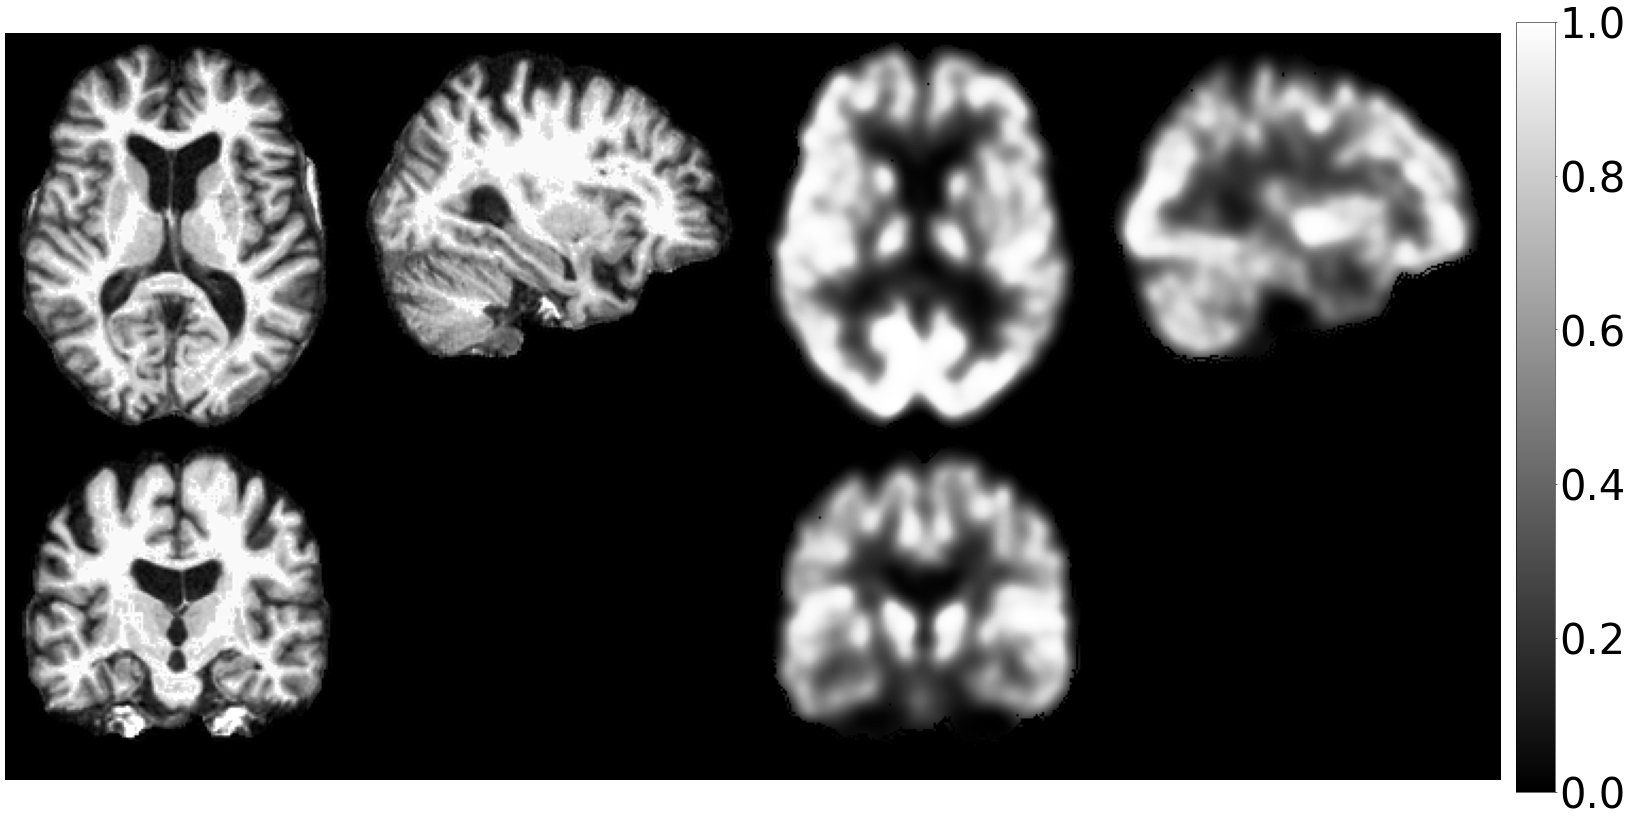

torch.Size([1, 1, 160, 192, 160])
torch.Size([1, 1, 160, 192, 160])


In [12]:
for batch in train_loader:
    image_1 = batch["mri"]
    label_1 = batch["pet"]
    names = batch["name"]  # Extract subject information

    # Print or visualize subject information
    for idx, name in enumerate(names):
        print(f"Subject name: {name}")

    compare_3d([image_1, label_1])
    break  # Uncomment to compare only the first batch
print(image_1.shape)
print(label_1.shape)


In [13]:
import torch
from transformers import AutoProcessor, AutoModel
import os
import numpy as np
from PIL import Image  # 导入 PIL.Image
import torch
from transformers import AutoProcessor, AutoModel
# 1. 加载 BiomedCLIP 模型和处理器
local_model_path = "/home/data/liutuo/code/BiomedCLIP"
processor = AutoProcessor.from_pretrained(local_model_path, trust_remote_code=True)
model = AutoModel.from_pretrained(local_model_path, trust_remote_code=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
model.eval()

# 2. 定义 BiomedCLIP 特征提取函数
def extract_pet_features_from_monai(batch, num_slices=160):

    pet_data = batch["pet"]  # 提取 PET 数据 (batch_size, 1, 160, 192, 160)
    pet_data = pet_data.squeeze(0).squeeze(0).numpy()  # 移除 batch 和通道维度 -> (160, 192, 160)
    
    # 提取 num_slices 张切片（均匀采样）
    slice_indices = np.linspace(0, pet_data.shape[2] - 1, num_slices, dtype=int)
    slices = [pet_data[:, :, i] for i in slice_indices]
    
    # 预处理切片 -> 224x224 RGB
    processed_slices = []
    for slice_2d in slices:
        slice_min, slice_max = slice_2d.min(), slice_2d.max()
        normalized_slice = (slice_2d - slice_min) / (slice_max - slice_min + 1e-5)
        img = Image.fromarray((normalized_slice * 255).astype(np.uint8)).resize((224, 224))
        img_rgb = np.stack([img] * 3, axis=-1)
        processed_slices.append(Image.fromarray(img_rgb.astype(np.uint8)))
    
    # 使用 BiomedCLIP 提取切片特征
    inputs = processor(images=processed_slices, return_tensors="pt").to(device)
    with torch.no_grad():
        slice_features = model.get_image_features(**inputs)  # (num_slices, 512)
    
    # 平均池化得到全局特征
    global_feature = torch.mean(slice_features, dim=0)  # (512,)
    return global_feature.cpu().detach()

# 3. 遍历 train_loader，提取所有样本的特征
pet_vectors = []
for i, batch in enumerate(train_loader):
    print(f"Processing batch {i+1}/{len(train_loader)}...")
    pet_vector = extract_pet_features_from_monai(batch)  # 提取单张 PET 图像的特征
    pet_vectors.append(pet_vector)

# 堆叠所有特征向量
pet_vectors = torch.stack(pet_vectors)  # Shape: (1129, 512)

# 4. 保存所有特征

output_path = "/home/data/liutuo/code/checkpoint/pet_vectors_from_monai.pt"
torch.save(pet_vectors, output_path)
print(f"所有 PET 特征向量已保存到 {output_path}")

Processing batch 1/1129...
Processing batch 2/1129...
Processing batch 3/1129...
Processing batch 4/1129...
Processing batch 5/1129...
Processing batch 6/1129...
Processing batch 7/1129...
Processing batch 8/1129...
Processing batch 9/1129...
Processing batch 10/1129...
Processing batch 11/1129...
Processing batch 12/1129...
Processing batch 13/1129...
Processing batch 14/1129...
Processing batch 15/1129...
Processing batch 16/1129...
Processing batch 17/1129...
Processing batch 18/1129...
Processing batch 19/1129...
Processing batch 20/1129...
Processing batch 21/1129...
Processing batch 22/1129...
Processing batch 23/1129...
Processing batch 24/1129...
Processing batch 25/1129...
Processing batch 26/1129...
Processing batch 27/1129...
Processing batch 28/1129...
Processing batch 29/1129...
Processing batch 30/1129...
Processing batch 31/1129...
Processing batch 32/1129...
Processing batch 33/1129...
Processing batch 34/1129...
Processing batch 35/1129...
Processing batch 36/1129...
P

In [39]:
import torch

# 加载 pet_vectors 和 c_pet
pet_vectors = torch.load("/home/data/liutuo/code/checkpoint/pet_vectors_from_monai.pt")  # 1129 x 512
c_pet = c_pet.to(pet_vectors.device)        # 确保 c_pet 在同一设备上

# 计算余弦相似度
cosine_similarity = torch.nn.functional.cosine_similarity(pet_vectors, c_pet)
print("余弦相似度 shape:", cosine_similarity.shape)  # 输出: (1129,)

# 输出前 10 张图像与文本的相似度
print("前 10 张图像的相似度:", cosine_similarity[:10].tolist())


余弦相似度 shape: torch.Size([1129])
前 10 张图像的相似度: [0.37795937061309814, 0.36883294582366943, 0.3901200294494629, 0.37322622537612915, 0.34821003675460815, 0.3874002993106842, 0.4001671075820923, 0.34616369009017944, 0.37827640771865845, 0.37967464327812195]


You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.


In [48]:
c_pet = pet_vectors[:1] # 获取第一个向量
cosine_similarity = torch.nn.functional.cosine_similarity(pet_vectors, c_pet )
print("前 10 张图像的相似度:", cosine_similarity[:50].tolist())

前 10 张图像的相似度: [1.0000001192092896, 0.976475179195404, 0.9871987700462341, 0.9593300819396973, 0.9807291030883789, 0.9941551089286804, 0.9733434915542603, 0.9554470181465149, 0.9889293313026428, 0.9901062250137329, 0.9867697358131409, 0.9804282188415527, 0.9881357550621033, 0.9832553863525391, 0.9812166094779968, 0.9901838898658752, 0.993047833442688, 0.9921106100082397, 0.9908559322357178, 0.9741983413696289, 0.9722592830657959, 0.9759377837181091, 0.9886829853057861, 0.9827890992164612, 0.9917446374893188, 0.9771476984024048, 0.9949201345443726, 0.9786103367805481, 0.9561196565628052, 0.9910063743591309, 0.9832730293273926, 0.9866911768913269, 0.9852231740951538, 0.9699524641036987, 0.984283447265625, 0.9460188150405884, 0.990909218788147, 0.9820204973220825, 0.9932302236557007, 0.9768381714820862, 0.9677891135215759, 0.9966800212860107, 0.9903854727745056, 0.993961751461029, 0.9788680672645569, 0.9863929152488708, 0.9894964694976807, 0.98930424451828, 0.9888702630996704, 0.9565072655

In [50]:
print(c_pet .shape)

torch.Size([1, 512])


In [51]:
import torch
import torch.nn.functional as F
from torch.optim.lr_scheduler import StepLR

def info_nce_loss(pet_vectors, c_pet, temperature=0.5):
    # 归一化向量
    pet_vectors = F.normalize(pet_vectors, dim=-1)
    c_pet = F.normalize(c_pet, dim=-1)

    # 计算全对全相似度
    logits = torch.matmul(pet_vectors, c_pet.T) / temperature
    logits = logits.expand(len(pet_vectors), len(pet_vectors))

    # 构造标签
    labels = torch.arange(logits.size(0), device=logits.device)

    # 计算 InfoNCE 损失
    loss = F.cross_entropy(logits, labels)
    return loss

# 加载特征
pet_vectors = torch.load("/home/data/liutuo/code/checkpoint/pet_vectors_from_monai.pt")
pet_vectors.requires_grad_(False)

# 初始化 c_pet

c_pet = torch.nn.Parameter(c_pet.clone())
c_pet = c_pet.to(pet_vectors.device)  
# 优化器和调度器
optimizer = torch.optim.Adam([c_pet], lr=1e-2)
scheduler = StepLR(optimizer, step_size=10, gamma=0.5)

# 训练参数
epochs = 50
temperature = 0.5

# 初始相似度
cosine_similarity = F.cosine_similarity(pet_vectors, c_pet)
print("初始前 10 张图像的余弦相似度:", cosine_similarity[:10].tolist())

# 训练
for epoch in range(epochs):
    optimizer.zero_grad()
    loss = info_nce_loss(pet_vectors, c_pet, temperature)
    loss.backward()

    # 调试信息
    print(f"Epoch {epoch + 1}/{epochs}, Loss: {loss.item()}")
    print("c_pet 梯度前 5 元素:", c_pet.grad[:5])

    optimizer.step()
    scheduler.step()

# 训练后相似度
cosine_similarity = F.cosine_similarity(pet_vectors, c_pet)
print("训练后前 10 张图像的余弦相似度:", cosine_similarity[:10].tolist())

# 保存优化后的 c_pet
torch.save(c_pet.detach(), "/home/data/liutuo/code/checkpoint/c_pet_optimized.pt")
print("优化后的 c_pet 已保存！")





You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.


初始前 10 张图像的余弦相似度: [1.0000001192092896, 0.976475179195404, 0.9871987700462341, 0.9593300819396973, 0.9807291030883789, 0.9941551089286804, 0.9733434915542603, 0.9554470181465149, 0.9889293313026428, 0.9901062250137329]
Epoch 1/50, Loss: 7.029090404510498
c_pet 梯度前 5 元素: tensor([[ 4.0961e-12, -1.0208e-11, -3.5768e-12, -4.3602e-12,  4.3601e-12,
         -6.8877e-12,  1.9302e-11, -5.0839e-12,  4.8915e-12,  4.1291e-12,
         -3.0442e-12,  1.1554e-12,  1.5036e-11, -7.7083e-12, -3.5635e-12,
         -4.6315e-12,  6.8381e-12, -1.5270e-11,  7.3046e-12, -6.1167e-12,
          1.4417e-11,  6.5349e-12,  4.7868e-12, -2.4969e-11, -1.7712e-11,
         -2.8379e-11, -9.0388e-12,  8.2845e-12,  1.0963e-11,  2.3051e-12,
         -5.7069e-12,  5.3809e-12, -9.5803e-13,  1.1918e-11,  1.0231e-11,
         -7.2881e-12, -1.5474e-12, -2.6751e-11,  2.7146e-12, -1.5480e-12,
         -1.3408e-11, -9.3818e-12,  5.3812e-12,  1.4542e-12,  4.0107e-12,
          1.1570e-11, -1.7392e-11,  4.3650e-12, -9.2534e-12,  3.

In [45]:
print("c_pet 类型:", type(c_pet))
print(c_pet.shape)

c_pet 类型: <class 'torch.nn.parameter.Parameter'>
torch.Size([512])


In [ ]:
import os
os.environ["TOKENIZERS_PARALLELISM"] = "false"
from torch.amp import GradScaler, autocast  # 从 torch.amp 导入 GradScaler

from generative.networks.nets import DiffusionModelUNet
from generative.networks.schedulers import DDPMScheduler,DDIMScheduler
from generative.inferers import DiffusionInferer
model= DiffusionModelUNet(
    spatial_dims=3,
    in_channels=1,#1,
    out_channels=1,
    num_channels=(32,64,64,128),
    attention_levels=(False,False,False,True),
    num_res_blocks=1,
    num_head_channels=(0,0,0, 128),
    with_conditioning=True,
    cross_attention_dim=512,
    use_flash_attention=True,
)



model.to(device)
scheduler = DDPMScheduler(prediction_type="v_prediction", num_train_timesteps=1000,schedule="scaled_linear_beta",
                          beta_start=0.0005, beta_end=0.0195)
scheduler.set_timesteps(num_inference_steps=1000)
optimizer= torch.optim.Adam(params=model.parameters(), lr=2.5e-5)
inferer = DiffusionInferer(scheduler)

# scheduler = DDIMScheduler(prediction_type='v_prediction',num_train_timesteps=1000,
#                            schedule="scaled_linear_beta",beta_start=0.0005, beta_end=0.0195)
# scheduler.set_timesteps(num_inference_steps=50)
# inferer = DiffusionInferer(scheduler)
# optimizer_1 = torch.optim.Adam(params=model_1.parameters(), lr=2.5e-5)



In [14]:
import os
import tempfile
import time
from liutuo_utils import donkey_noise_like
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from monai import transforms
from monai.apps import DecathlonDataset
from monai.config import print_config
from monai.data import DataLoader
from monai.utils import set_determinism
from torch.cuda.amp import GradScaler, autocast
from tqdm import tqdm
from torch.amp import GradScaler, autocast  # 从 torch.amp 导入 GradScaler





n_epochs =120
val_interval =10
epoch_loss_list = []
val_epoch_loss_list = []
scaler = GradScaler()  
total_start = time.time()
checkpoint_dir = '/home/data/liutuo/code/checkpoint/mri2pet-pretrain pet-mri2pet/first part'

# 定义裁剪的最小值和最大值
clip_sample_min = 0  # 设置合适的最小值
clip_sample_max = 1   # 设置合适的最大值

for epoch in range(n_epochs):
    model.train()
    epoch_loss = 0
    progress_bar = tqdm(enumerate(train_loader), total=len(train_loader), ncols=70)
    progress_bar.set_description(f"Epoch {epoch}")
    for step, data in progress_bar:

        
        seg = data["pet"].to(device) # this is the ground truth segmentation
        noise= donkey_noise_like(seg).to(device)
        images=noise
        pet_index=data["pet_index"].to(device)
        optimizer.zero_grad(set_to_none=True)
        timesteps = torch.randint(0, 1000, (len(images),)).to(device)  # pick a random time step t
        
        
        with autocast(device_type='cuda', enabled=True):
        
    
            # Create time_embedding
            time_embedding = torch.randint(
                0, 1000, (images.shape[0],), device=images.device
            ).long()
            
            if epoch >=100:
               time_embedding = torch.tensor([0], device=images.device, dtype=torch.long)
            # Create time
            t = time_embedding.float() / 1000

            # Get the v-prediction
            # print(t)
            # print(time_embedding)
            x_t = t * seg + (1 - t) * images
            v_prediction = model(x=x_t, timesteps=time_embedding,context=pet_index)
            
            

            # Get the loss
            # print(t)
            # print(time_embedding)
            v = seg - images
            loss = F.mse_loss(v.float(), v_prediction.float())
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        epoch_loss += loss.item()
        progress_bar.set_postfix({"loss": epoch_loss / (step + 1)})
        
        torch.cuda.empty_cache()
    
    epoch_loss_list.append(epoch_loss / (step + 1))
    if (epoch + 1) % val_interval == 0:
        model.eval()
        val_epoch_loss = 0
        for step, data_val in enumerate(val_loader):

            seg = data_val["pet"].to(device)  # this is the ground truth segmentation
            noise= donkey_noise_like(seg).to(device)
            images=noise
            pet_index=data["pet_index"].to(device)
            # timesteps = torch.randint(0, 1000, (len(images),)).to(device)
            
            x_t = images
            N_sample = 1
            N_sample_tensor = torch.tensor(N_sample, dtype=torch.float32)
            # progress_bar = tqdm([(i / (N_sample)) for i in range(N_sample)])
            progress_bar = [(i / (N_sample)) for i in range(N_sample)]
            for t in progress_bar:  # go through the noising process
                with autocast(device_type='cuda',enabled=False):
                    with torch.no_grad():
                        time_embedding = int(t * 1000)
                        # print(t)
                        # print(time_embedding)
                        v_output = model(x = x_t, timesteps=torch.Tensor((time_embedding,)).to(x_t.device),context=pet_index)
                        x_t = x_t + (v_output / N_sample_tensor)
                        x_t = torch.clamp(x_t, min=clip_sample_min, max=clip_sample_max)
                
            
            val_loss = F.mse_loss(x_t.float(),  seg.float())
            val_epoch_loss += val_loss.item()
            torch.cuda.empty_cache()
        print("Epoch", epoch + 1, "Validation loss", val_epoch_loss / (step + 1))
        val_epoch_loss_list.append(val_epoch_loss / (step + 1))
         # Saving model parameters
        print('epoch:', epoch + 1)
        print('learning rate:', optimizer.state_dict()['param_groups'][0]['lr'])
        checkpoint = {
            'model': model.state_dict(),
            'optimizer': optimizer.state_dict(),
            'epoch': epoch
        }
        torch.save(checkpoint, f'{checkpoint_dir}/first_part_{epoch + 1}.pth')
        print('Saved all parameters!\n')
        
        current_img =  x_t.to('cpu')
        labels = seg.to('cpu')
        compare_3d([images,labels, current_img])
        compare_3d_jet([current_img - labels])

Epoch 0:   0%|                                | 0/800 [00:01<?, ?it/s]


OutOfMemoryError: CUDA out of memory. Tried to allocate 1.17 GiB. GPU 1 has a total capacity of 47.53 GiB of which 880.50 MiB is free. Process 14382 has 2.11 GiB memory in use. Process 14762 has 1.98 GiB memory in use. Process 15282 has 2.11 GiB memory in use. Process 15389 has 2.11 GiB memory in use. Process 15493 has 2.11 GiB memory in use. Process 318978 has 4.13 GiB memory in use. Process 2112368 has 6.61 GiB memory in use. Process 2113424 has 6.35 GiB memory in use. Including non-PyTorch memory, this process has 19.11 GiB memory in use. Of the allocated memory 16.76 GiB is allocated by PyTorch, and 2.04 GiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://pytorch.org/docs/stable/notes/cuda.html#environment-variables)

In [ ]:
import os
os.environ["TOKENIZERS_PARALLELISM"] = "false"
from torch.amp import GradScaler, autocast  # 从 torch.amp 导入 GradScaler

from generative.networks.nets import DiffusionModelUNet
from generative.networks.schedulers import DDPMScheduler,DDIMScheduler
from generative.inferers import DiffusionInferer
model_1= DiffusionModelUNet(
    spatial_dims=3,
    in_channels=1,#1,
    out_channels=1,
    num_channels=(32,64,64,128),
    attention_levels=(False,False,False,True),
    num_res_blocks=1,
    num_head_channels=(0,0,0, 128),
    with_conditioning=True,
    cross_attention_dim=512,
    use_flash_attention=True,
)



model_1.to(device)
scheduler = DDPMScheduler(prediction_type="v_prediction", num_train_timesteps=1000,schedule="scaled_linear_beta",
                          beta_start=0.0005, beta_end=0.0195)
scheduler.set_timesteps(num_inference_steps=1000)
optimizer_1= torch.optim.Adam(params=model.parameters(), lr=2.5e-5)
inferer = DiffusionInferer(scheduler)

In [ ]:
checkpoint_path = '/home/data/liutuo/code/checkpoint/mri2pet-pretrain pet-mri2pet/first part/first_part_120.pth'
source_weight=torch.load(checkpoint_path)["model"]
model_state_dict=model_1.state_dict()
for key in model_state_dict.keys():
    #if key in target_weight.keys():
    if model_state_dict[key].shape==source_weight[key].shape:
        model_state_dict[key]=source_weight[key]
    else:
        # expand dims with copied value
        print(f"{key} shape dismatch: source {model_state_dict[key].shape}, target {source_weight[key].shape}")
        repeat_times=[yy//xx for yy,xx in zip(model_state_dict[key].shape,source_weight[key].shape)]
        model_state_dict[key]=source_weight[key].repeat(repeat_times)

model_1.load_state_dict(model_state_dict)
model_1.to(device)

In [ ]:
import os
import tempfile
import time
from liutuo_utils import donkey_noise_like
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from monai import transforms
from monai.apps import DecathlonDataset
from monai.config import print_config
from monai.data import DataLoader
from monai.utils import set_determinism
from torch.cuda.amp import GradScaler, autocast
from tqdm import tqdm
from torch.amp import GradScaler, autocast  # 从 torch.amp 导入 GradScaler





n_epochs = 140
val_interval =10
epoch_loss_list = []
val_epoch_loss_list = []
scaler = GradScaler()  
total_start = time.time()
checkpoint_dir = '/home/data/liutuo/code/checkpoint/mri2pet-pretrain pet-mri2pet/second part'

# 定义裁剪的最小值和最大值
clip_sample_min = 0  # 设置合适的最小值
clip_sample_max = 1   # 设置合适的最大值

for epoch in range(n_epochs):
    model_1.train()
    epoch_loss = 0
    progress_bar = tqdm(enumerate(train_loader), total=len(train_loader), ncols=70)
    progress_bar.set_description(f"Epoch {epoch}")
    for step, data in progress_bar:
        images = data["mri"].to(device)
        seg = data["pet"].to(device) # this is the ground truth segmentation
        pet_index=data["pet_index"].to(device)
        optimizer_1.zero_grad(set_to_none=True)
        timesteps = torch.randint(0, 1000, (len(images),)).to(device)  # pick a random time step t
        
        
        with autocast(device_type='cuda', enabled=True):
        
    
            # Create time_embedding
            time_embedding = torch.randint(
                0, 1000, (images.shape[0],), device=images.device
            ).long()
            
            if epoch >=100:
               time_embedding = torch.tensor([0], device=images.device, dtype=torch.long)
            # Create time
            t = time_embedding.float() / 1000

            # Get the v-prediction
            # print(t)
            # print(time_embedding)
            x_t = t * seg + (1 - t) * images
            v_prediction = model_1(x=x_t, timesteps=time_embedding,context=pet_index)
            
            

            # Get the loss
            # print(t)
            # print(time_embedding)
            v = seg - images
            loss = F.mse_loss(v.float(), v_prediction.float())
        scaler.scale(loss).backward()
        scaler.step(optimizer_1)
        scaler.update()
        epoch_loss += loss.item()
        progress_bar.set_postfix({"loss": epoch_loss / (step + 1)})
        
        torch.cuda.empty_cache()
    
    epoch_loss_list.append(epoch_loss / (step + 1))
    if (epoch + 1) % val_interval == 0:
        model_1.eval()
        val_epoch_loss = 0
        for step, data_val in enumerate(val_loader):
            images = data_val["mri"].to(device)
            seg = data_val["pet"].to(device)  # this is the ground truth segmentation
            pet_index=data["pet_index"].to(device)
            # timesteps = torch.randint(0, 1000, (len(images),)).to(device)
            
            x_t = images
            N_sample = 1
            N_sample_tensor = torch.tensor(N_sample, dtype=torch.float32)
            # progress_bar = tqdm([(i / (N_sample)) for i in range(N_sample)])
            progress_bar = [(i / (N_sample)) for i in range(N_sample)]
            for t in progress_bar:  # go through the noising process
                with autocast(device_type='cuda',enabled=False):
                    with torch.no_grad():
                        time_embedding = int(t * 1000)
                        # print(t)
                        # print(time_embedding)
                        v_output = model_1(x = x_t, timesteps=torch.Tensor((time_embedding,)).to(x_t.device),context=pet_index)
                        x_t = x_t + (v_output / N_sample_tensor)
                        x_t = torch.clamp(x_t, min=clip_sample_min, max=clip_sample_max)
                
            
            val_loss = F.mse_loss(x_t.float(),  seg.float())
            val_epoch_loss += val_loss.item()
            torch.cuda.empty_cache()
        print("Epoch", epoch + 1, "Validation loss", val_epoch_loss / (step + 1))
        val_epoch_loss_list.append(val_epoch_loss / (step + 1))
         # Saving model parameters
        print('epoch:', epoch + 1)
        print('learning rate:', optimizer_1.state_dict()['param_groups'][0]['lr'])
        checkpoint = {
            'model': model_1.state_dict(),
            'optimizer': optimizer_1.state_dict(),
            'epoch': epoch
        }
        torch.save(checkpoint, f'{checkpoint_dir}/second_part_{epoch + 1}.pth')
        print('Saved all parameters!\n')
        
        current_img =  x_t.to('cpu')
        labels = seg.to('cpu')
        compare_3d([images,labels, current_img])
        compare_3d_jet([current_img - labels])
        from generative.metrics import SSIMMetric
        from monai.metrics import (MAEMetric,MSEMetric,PSNRMetric,)
        ssim_metric = SSIMMetric(spatial_dims=3, data_range=1.0,kernel_size=7)
        psnr_metric=PSNRMetric(1.0)

        ssim_value = ssim_metric(labels, current_img)
        psnr_value = psnr_metric(labels, current_img)

        print(f"SSIM: {ssim_value.mean().item()}")
        print(f"PSNR: {psnr_value.mean().item()}") 

# total_time = time.time() - total_start
# print(f"train diffusion completed, total time: {total_time}.")
# plt.style.use("seaborn-bright")
# plt.title("Learning Curves Diffusion Model", fontsize=20)
# plt.plot(np.linspace(1, n_epochs, n_epochs), epoch_loss_list, color="C0", linewidth=2.0, label="Train")
# plt.plot(
#     np.linspace(val_interval, n_epochs, int(n_epochs / val_interval)),
#     val_epoch_loss_list,
#     color="C1",
#     linewidth=2.0,
#     label="Validation",
# )
# plt.yticks(fontsize=12)
# plt.xticks(fontsize=12)
# plt.xlabel("Epochs", fontsize=16)
# plt.ylabel("Loss", fontsize=16)
# plt.legend(prop={"size": 14})
# plt.show()

In [ ]:
import os
import tempfile
import time
from liutuo_utils import donkey_noise_like
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from monai import transforms
from monai.apps import DecathlonDataset
from monai.config import print_config
from monai.data import DataLoader
from monai.utils import set_determinism
from torch.cuda.amp import GradScaler, autocast
from tqdm import tqdm
from torch.amp import GradScaler, autocast  # 从 torch.amp 导入 GradScaler

n_epochs = 200
val_interval =10
epoch_loss_list = []
val_epoch_loss_list = []
scaler = GradScaler()  
total_start = time.time()
# Load the checkpoint
checkpoint_dir = '/home/data/liutuo/code/checkpoint/mri2pet all data-_add personal clip-_flow'
checkpoint = torch.load(f'{checkpoint_dir}/noise2image about mri2pet_method_two_second_part_100.pth')
model.load_state_dict(checkpoint['model'])
optimizer.load_state_dict(checkpoint['optimizer'])
start_epoch = checkpoint['epoch'] + 1  # Start from the next epoch after the last saved one

# Set new training parameters
new_epochs =20  # Number of additional epochs to train
total_epochs = start_epoch + new_epochs
val_interval = 1  # Keep validation interval unchanged
epoch_loss_list = []  # Initialize epoch loss list
val_epoch_loss_list = []  # Initialize validation epoch loss list

# Training loop
# 定义裁剪的最小值和最大值
clip_sample_min = 0  # 设置合适的最小值
clip_sample_max = 1.0   # 设置合适的最大值

for epoch in range(start_epoch, total_epochs):  # Start from `start_epoch`
    model.train()
    epoch_loss = 0
    progress_bar = tqdm(enumerate(train_loader), total=len(train_loader), ncols=70)
    progress_bar.set_description(f"Epoch {epoch}")
    for step, data in progress_bar:
        images = data["mri"].to(device)
        seg = data["pet"].to(device)  # Ground truth segmentation
        pet_index = data["pet_index"].to(device)
        optimizer.zero_grad(set_to_none=True)
        timesteps = torch.randint(0, 1000, (len(images),)).to(device)  # Random time step t
        
        with autocast(device_type='cuda', enabled=True):
            # Create time_embedding
            time_embedding = torch.randint(0, 1000, (images.shape[0],), device=images.device).long()
            if epoch >= 100:
               time_embedding = torch.tensor([0], device=images.device, dtype=torch.long)
            
            t = time_embedding.float() / 1000  # Convert time to float scale

            # Get the v-prediction
            x_t = t * seg + (1 - t) * images
            v_prediction = model(x=x_t, timesteps=time_embedding, context=pet_index)

            # # **裁剪预测值**
            # v_prediction = torch.clamp(v_prediction, min=clip_sample_min, max=clip_sample_max)

            # Calculate the loss
            v = seg - images
            loss = F.mse_loss(v.float(), v_prediction.float())
        
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        epoch_loss += loss.item()
        progress_bar.set_postfix({"loss": epoch_loss / (step + 1)})
        
        torch.cuda.empty_cache()
    
    epoch_loss_list.append(epoch_loss / (step + 1))
    
    # Validation
    if (epoch + 1) % val_interval == 0:
        model.eval()
        val_epoch_loss = 0
        for step, data_val in enumerate(val_loader):
            images = data_val["mri"].to(device)
            seg = data_val["pet"].to(device)  # Ground truth segmentation
            pet_index = data["pet_index"].to(device)
            
            x_t = images
            N_sample = 1
            N_sample_tensor = torch.tensor(N_sample, dtype=torch.float32)
            progress_bar = [(i / N_sample) for i in range(N_sample)]
            for t in progress_bar:  # Iterate through noising process
                with autocast(device_type='cuda', enabled=False):
                    with torch.no_grad():
                        time_embedding = int(t * 1000)
                        v_output = model(x=x_t, timesteps=torch.Tensor((time_embedding,)).to(x_t.device), context=pet_index)
                        
                        # # **裁剪预测值**
                        # v_output = torch.clamp(v_output, min=clip_sample_min, max=clip_sample_max)
                        
                        x_t = x_t + (v_output / N_sample_tensor)
                        x_t = torch.clamp(x_t, min=clip_sample_min, max=clip_sample_max)
                
            val_loss = F.mse_loss(x_t.float(), seg.float())
            val_epoch_loss += val_loss.item()
            torch.cuda.empty_cache()
        
        print("Epoch", epoch + 1, "Validation loss", val_epoch_loss / (step + 1))
        val_epoch_loss_list.append(val_epoch_loss / (step + 1))
        
        # Save model parameters
        print('Epoch:', epoch + 1)
        print('Learning rate:', optimizer.state_dict()['param_groups'][0]['lr'])
        checkpoint = {
            'model': model.state_dict(),
            'optimizer': optimizer.state_dict(),
            'epoch': epoch
        }
        torch.save(checkpoint, f'{checkpoint_dir}/noise2image about mri2pet_method_two_second_part_{epoch + 1}.pth')
        print('Saved all parameters!\n')

        current_img =  x_t.to('cpu')
        labels = seg.to('cpu')
        compare_3d([images, labels, current_img])
        compare_3d_jet([current_img - labels])
        from generative.metrics import SSIMMetric
        from monai.metrics import (MAEMetric, MSEMetric, PSNRMetric)
        ssim_metric = SSIMMetric(spatial_dims=3, data_range=1.0, kernel_size=7)
        psnr_metric = PSNRMetric(1.0)

        ssim_value = ssim_metric(labels, current_img)
        psnr_value = psnr_metric(labels, current_img)

        print(f"SSIM: {ssim_value.mean().item()}")
        print(f"PSNR: {psnr_value.mean().item()}") 


In [ ]:
import os
import tempfile
import time
from liutuo_utils import donkey_noise_like
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from monai import transforms
from monai.apps import DecathlonDataset
from monai.config import print_config
from monai.data import DataLoader
from monai.utils import set_determinism
from torch.cuda.amp import GradScaler, autocast
from tqdm import tqdm
from torch.amp import GradScaler, autocast  # 从 torch.amp 导入 GradScaler

n_epochs = 200
val_interval =10
epoch_loss_list = []
val_epoch_loss_list = []
scaler = GradScaler()  
total_start = time.time()
# Load the checkpoint
checkpoint_dir = '/home/data/liutuo/code/checkpoint/mri2pet all data-_add personal clip-_flow'
checkpoint = torch.load(f'{checkpoint_dir}/noise2image about mri2pet_method_two_second_part_111.pth')
model.load_state_dict(checkpoint['model'])
optimizer.load_state_dict(checkpoint['optimizer'])
start_epoch = checkpoint['epoch'] + 1  # Start from the next epoch after the last saved one

# Set new training parameters
new_epochs =10  # Number of additional epochs to train
total_epochs = start_epoch + new_epochs
val_interval = 1  # Keep validation interval unchanged
epoch_loss_list = []  # Initialize epoch loss list
val_epoch_loss_list = []  # Initialize validation epoch loss list

# Training loop
# 定义裁剪的最小值和最大值
clip_sample_min = 0  # 设置合适的最小值
clip_sample_max = 1.0   # 设置合适的最大值

for epoch in range(start_epoch, total_epochs):  # Start from `start_epoch`
    model.train()
    epoch_loss = 0
    progress_bar = tqdm(enumerate(train_loader), total=len(train_loader), ncols=70)
    progress_bar.set_description(f"Epoch {epoch}")
    for step, data in progress_bar:
        images = data["mri"].to(device)
        seg = data["pet"].to(device)  # Ground truth segmentation
        pet_index = data["pet_index"].to(device)
        optimizer.zero_grad(set_to_none=True)
        timesteps = torch.randint(0, 1000, (len(images),)).to(device)  # Random time step t
        
        with autocast(device_type='cuda', enabled=True):
            # Create time_embedding
            time_embedding = torch.randint(0, 1000, (images.shape[0],), device=images.device).long()
            if epoch >= 100:
               time_embedding = torch.tensor([0], device=images.device, dtype=torch.long)
            
            t = time_embedding.float() / 1000  # Convert time to float scale

            # Get the v-prediction
            x_t = t * seg + (1 - t) * images
            v_prediction = model(x=x_t, timesteps=time_embedding, context=pet_index)

            # # **裁剪预测值**
            # v_prediction = torch.clamp(v_prediction, min=clip_sample_min, max=clip_sample_max)

            # Calculate the loss
            v = seg - images
            loss = F.mse_loss(v.float(), v_prediction.float())
        
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        epoch_loss += loss.item()
        progress_bar.set_postfix({"loss": epoch_loss / (step + 1)})
        
        torch.cuda.empty_cache()
    
    epoch_loss_list.append(epoch_loss / (step + 1))
    
    # Validation
    if (epoch + 1) % val_interval == 0:
        model.eval()
        val_epoch_loss = 0
        for step, data_val in enumerate(val_loader):
            images = data_val["mri"].to(device)
            seg = data_val["pet"].to(device)  # Ground truth segmentation
            pet_index = data["pet_index"].to(device)
            
            x_t = images
            N_sample = 1
            N_sample_tensor = torch.tensor(N_sample, dtype=torch.float32)
            progress_bar = [(i / N_sample) for i in range(N_sample)]
            for t in progress_bar:  # Iterate through noising process
                with autocast(device_type='cuda', enabled=False):
                    with torch.no_grad():
                        time_embedding = int(t * 1000)
                        v_output = model(x=x_t, timesteps=torch.Tensor((time_embedding,)).to(x_t.device), context=pet_index)
                        
                        # # **裁剪预测值**
                        # v_output = torch.clamp(v_output, min=clip_sample_min, max=clip_sample_max)
                        
                        x_t = x_t + (v_output / N_sample_tensor)
                        x_t = torch.clamp(x_t, min=clip_sample_min, max=clip_sample_max)
                
            val_loss = F.mse_loss(x_t.float(), seg.float())
            val_epoch_loss += val_loss.item()
            torch.cuda.empty_cache()
        
        print("Epoch", epoch + 1, "Validation loss", val_epoch_loss / (step + 1))
        val_epoch_loss_list.append(val_epoch_loss / (step + 1))
        
        # Save model parameters
        print('Epoch:', epoch + 1)
        print('Learning rate:', optimizer.state_dict()['param_groups'][0]['lr'])
        checkpoint = {
            'model': model.state_dict(),
            'optimizer': optimizer.state_dict(),
            'epoch': epoch
        }
        torch.save(checkpoint, f'{checkpoint_dir}/noise2image about mri2pet_method_two_second_part_{epoch + 1}.pth')
        print('Saved all parameters!\n')

        current_img =  x_t.to('cpu')
        labels = seg.to('cpu')
        compare_3d([images, labels, current_img])
        compare_3d_jet([current_img - labels])
        from generative.metrics import SSIMMetric
        from monai.metrics import (MAEMetric, MSEMetric, PSNRMetric)
        ssim_metric = SSIMMetric(spatial_dims=3, data_range=1.0, kernel_size=7)
        psnr_metric = PSNRMetric(1.0)

        ssim_value = ssim_metric(labels, current_img)
        psnr_value = psnr_metric(labels, current_img)

        print(f"SSIM: {ssim_value.mean().item()}")
        print(f"PSNR: {psnr_value.mean().item()}") 


In [ ]:
from generative.metrics import SSIMMetric
from monai.metrics import MAEMetric, MSEMetric, PSNRMetric
import torch.nn.functional as F
# Initialize metrics
ssim_metric = SSIMMetric(spatial_dims=3, data_range=1.0, kernel_size=7)
psnr_metric = PSNRMetric(1.0)
mae_metric = MAEMetric()
mse_metric = MSEMetric()

# Initialize accumulators for average metrics
ssim_total = 0
psnr_total = 0
mse_total = 0
mae_total = 0
val_epoch_loss = 0
num_batches = 0
clip_sample_min = 0  # 设置合适的最小值
clip_sample_max = 1.0   # 设置合适的最大值
# Load the saved checkpoint
checkpoint_path = "/home/data/liutuo/code/checkpoint/mri2pet all data-_add personal clip-_flow/noise2image about mri2pet_method_two_second_part_141.pth"
checkpoint = torch.load(checkpoint_path)
model.load_state_dict(checkpoint['model'])
optimizer.load_state_dict(checkpoint['optimizer'])
model.eval()  # Set the model to evaluation mode

# Evaluation loop
with torch.no_grad():
    for step, data_val in enumerate(val_loader):
        images = data_val["mri"].to(device)
        seg = data_val["pet"].to(device)  # Ground truth segmentation
        pet_index = data_val["pet_index"].to(device)
        names = data_val["name"]  # Get subject names

        x_t = images
        N_sample = 1
        N_sample_tensor = torch.tensor(N_sample, dtype=torch.float32)
        progress_bar = [(i / N_sample) for i in range(N_sample)]
        t=0
        for t in progress_bar:
            with autocast(device_type='cuda', enabled=False):
                time_embedding = torch.tensor([0], device=images.device, dtype=torch.long)
                time_embedding = int(t * 1000)
                v_output = model(x=x_t, timesteps=torch.Tensor((time_embedding,)).to(x_t.device), context=pet_index)
                x_t = x_t + (v_output / N_sample_tensor)
                x_t = torch.clamp(x_t, min=clip_sample_min, max=clip_sample_max)

        # Calculate MSE loss for this batch
        val_loss = F.mse_loss(x_t.float(), seg.float())
        val_epoch_loss += val_loss.item()

        # Move data to CPU for metric calculations
        current_img = x_t.to('cpu')
        labels = seg.to('cpu')

        # Calculate metrics for the current batch
        ssim_value = ssim_metric(labels, current_img).mean().item()
        psnr_value = psnr_metric(labels, current_img).mean().item()
        mse_value = mse_metric(labels, current_img).mean().item()
        mae_value = mae_metric(labels, current_img).mean().item()

        # Accumulate metrics for averaging
        ssim_total += ssim_value
        psnr_total += psnr_value
        mse_total += mse_value
        mae_total += mae_value
        num_batches += 1

        # Print metrics for the current batch
        for idx, name in enumerate(names):
            print(f"Subject name: {name}")
            print(f"SSIM: {ssim_value}, PSNR: {psnr_value}, MSE: {mse_value}, MAE: {mae_value}")

    # Calculate and print average metrics
    avg_ssim = ssim_total / num_batches
    avg_psnr = psnr_total / num_batches
    avg_mse = mse_total / num_batches
    avg_mae = mae_total / num_batches

    print("Average metrics over all validation batches:")
    print(f"SSIM: {avg_ssim}")
    print(f"PSNR: {avg_psnr}")
    print(f"MSE: {avg_mse}")
    print(f"MAE: {avg_mae}")
    print("Validation loss:", val_epoch_loss / num_batches)


In [ ]:
from generative.metrics import SSIMMetric
from monai.metrics import MAEMetric, MSEMetric, PSNRMetric
import torch.nn.functional as F
# Initialize metrics
ssim_metric = SSIMMetric(spatial_dims=3, data_range=1.0, kernel_size=7)
psnr_metric = PSNRMetric(1.0)
mae_metric = MAEMetric()
mse_metric = MSEMetric()

# Initialize accumulators for average metrics
ssim_total = 0
psnr_total = 0
mse_total = 0
mae_total = 0
val_epoch_loss = 0
num_batches = 0

# Load the saved checkpoint
checkpoint_path = "/home/data/liutuo/code/checkpoint/mri2pet all data-_add personal clip-_flow/noise2image about mri2pet_method_two_second_part_10.pth"
checkpoint = torch.load(checkpoint_path)
model.load_state_dict(checkpoint['model'])
optimizer.load_state_dict(checkpoint['optimizer'])
model.eval()  # Set the model to evaluation mode
clip_sample_min = 0  # 设置合适的最小值
clip_sample_max = 1.0   # 设置合适的最大值

# Evaluation loop
with torch.no_grad():
    for step, data_val in enumerate(train_loader):
        if step >= 5:  # Stop after processing the first 20 batches
            break

        images = data_val["mri"].to(device)
        seg = data_val["pet"].to(device)  # Ground truth segmentation
        pet_index = data_val["pet_index"].to(device)
        names = data_val["name"]  # Get subject names
        time_embedding = torch.randint(0, 1000, (images.shape[0],), device=images.device).long()
        time_embedding = torch.tensor([0], device=images.device, dtype=torch.long)
        t = time_embedding.float() / 1000  # Convert time to float scale
        time_embedding = torch.tensor([0], device=images.device, dtype=torch.long)

        x_t = images
        N_sample =1
        N_sample_tensor = torch.tensor(N_sample, dtype=torch.float32)
        progress_bar = [(i / N_sample) for i in range(N_sample)]
        
        for t in progress_bar:
            with autocast(device_type='cuda', enabled=False):

                time_embedding = int(t * 1000)
                time_embedding = torch.tensor([0], device=images.device, dtype=torch.long)

                v_output = model(x=x_t, timesteps=torch.Tensor((time_embedding,)).to(x_t.device), context=pet_index)
                x_t = x_t + (v_output / N_sample_tensor)
                x_t = torch.clamp(x_t, min=clip_sample_min, max=clip_sample_max)

        # Calculate MSE loss for this batch
        val_loss = F.mse_loss(x_t.float(), seg.float())
        val_epoch_loss += val_loss.item()


        current_img =  x_t.to('cpu')
        labels = seg.to('cpu')
        compare_3d([images,labels, current_img])
        compare_3d_jet([current_img - labels])
        from generative.metrics import SSIMMetric
        from monai.metrics import (MAEMetric,MSEMetric,PSNRMetric,)
        ssim_metric = SSIMMetric(spatial_dims=3, data_range=1.0,kernel_size=7)
        psnr_metric=PSNRMetric(1.0)

        ssim_value = ssim_metric(labels, current_img)
        psnr_value = psnr_metric(labels, current_img)

        print(f"SSIM: {ssim_value.mean().item()}")
        print(f"PSNR: {psnr_value.mean().item()}") 

In [ ]:
import torch
import numpy as np
from tqdm import tqdm
from generative.metrics import SSIMMetric

# 加载保存的模型参数
checkpoint_path = "/home/data/liutuo/code/checkpoint/mri2pet all data-_add personal clip-_flow/noise2image about mri2pet_method_two_second_part_10.pth"
checkpoint = torch.load(checkpoint_path)
model.load_state_dict(checkpoint['model'])
optimizer.load_state_dict(checkpoint['optimizer'])
model.eval()  # Set the model to evaluation mode
clip_sample_min = 0  # 设置合适的最小值
clip_sample_max = 1.0   # 设置合适的最大值
model.to(device)

# 初始化SSIM度量
ssim_metric = SSIMMetric(spatial_dims=3, data_range=1.0, kernel_size=11)

# 遍历数据集，查找特定样本名称
for batch in train_loader:
    names = batch["name"]  # 提取样本名称

    # 查找名称为 "130_S_0460" 的样本
    if "002_S_2010" not in names:
        continue  # 如果没有找到该样本，继续下一个 batch

    # 获取该样本的 MRI 输入图像和 PET 标签
    images= batch["mri"].to(device)
    labels = batch["pet"].to(device)
    pet_index = batch["pet_index"].to(device)
    time_embedding = torch.randint(0, 1000, (images.shape[0],), device=images.device).long()
    time_embedding = torch.tensor([0], device=images.device, dtype=torch.long)
    t = time_embedding.float() / 1000  # Convert time to float scale
    time_embedding = torch.tensor([0], device=images.device, dtype=torch.long)

    x_t = images
    N_sample =1
    N_sample_tensor = torch.tensor(N_sample, dtype=torch.float32)
    progress_bar = [(i / N_sample) for i in range(N_sample)]
    
    for t in progress_bar:
        with autocast(device_type='cuda', enabled=False):

            time_embedding = int(t * 1000)
            time_embedding = torch.tensor([0], device=images.device, dtype=torch.long)

            v_output = model(x=x_t, timesteps=torch.Tensor((time_embedding,)).to(x_t.device), context=pet_index)
            x_t = x_t + (v_output / N_sample_tensor)
            x_t = torch.clamp(x_t, min=clip_sample_min, max=clip_sample_max)
    # 将结果移回CPU
    current_img = x_t.to('cpu')
    labels = labels.to('cpu')
    from generative.metrics import SSIMMetric
    from monai.metrics import (MAEMetric, MSEMetric, PSNRMetric,)

    # 计算当前采样的SSIM
    ssim_value = ssim_metric(labels, current_img)

    # 可视化采样结果
    compare_3d([images, labels, current_img])
    compare_3d_jet([images, labels, current_img])
    compare_3d_jet([current_img - labels])

    # 计算并输出PSNR和SSIM
    psnr_metric = PSNRMetric(1.0)
    ssim_value = ssim_metric(labels, current_img)
    psnr_value = psnr_metric(labels, current_img)

    print(f"SSIM: {ssim_value.mean().item()}")
    print(f"PSNR: {psnr_value.mean().item()}")

    # 找到并处理完 "130_S_0460" 样本后，退出循环
    break

In [ ]:
print(current_img.shape)

In [ ]:
import os
import torch
import nibabel as nib
import numpy as np
from monai.transforms import Orientationd, EnsureChannelFirstd
from monai.data import MetaTensor

# 保存路径
save_dir = "/home/data/liutuo/code/test"
os.makedirs(save_dir, exist_ok=True)

# 将张量转换为 NIfTI 文件并保存
def save_nifti(tensor, save_path, orientation_axcodes="LPI"):
    # 去掉前两维度，变成 3D
    array = tensor.squeeze().detach().cpu().numpy()


    # 创建 NIfTI 图像
    nii_img = nib.Nifti1Image(array, affine=np.eye(4))
    
    # 转换为 MetaTensor
    meta_tensor = MetaTensor(array, affine=np.eye(4))
    
    # 调整方向为 LPI
    orientation =mt.Orientationd(keys=["image"], axcodes="LPI")
    oriented_tensor = orientation({"image": meta_tensor})["image"]
    
    # 保存为 NIfTI 文件
    oriented_array = oriented_tensor.numpy()
    oriented_nii_img = nib.Nifti1Image(oriented_array, affine=np.eye(4))
    nib.save(oriented_nii_img, save_path)
    print(f"Saved: {save_path}")

# 保存 `input_img`
save_nifti(images, os.path.join(save_dir, "input_img.nii.gz"))

# 保存 `labels`
save_nifti(labels, os.path.join(save_dir, "labels.nii.gz"))

# 保存 `current_img`
save_nifti(current_img, os.path.join(save_dir, "current_img.nii.gz"))

In [ ]:
import os
import torch
import nibabel as nib  # 用于保存为 .nii.gz 格式
from monai.transforms import Orientationd
from monai.data import MetaTensor

# 保存路径
save_dir = "/home/data/liutuo/code/liutuo_data/ADNI1+2_baseline/flow_generated_pet"
os.makedirs(save_dir, exist_ok=True)

# 定义保存函数
def save_nifti(tensor, save_path, orientation_axcodes="LPI"):
    # 去掉前两维度，变成 3D
    array = tensor.squeeze().cpu().numpy()

    # 创建 NIfTI 图像
    nii_img = nib.Nifti1Image(array, affine=np.eye(4))
    
    # 转换为 MetaTensor
    meta_tensor = MetaTensor(array, affine=np.eye(4))
    
    # 调整方向为指定的 axcodes
    orientation = Orientationd(keys=["image"], axcodes=orientation_axcodes)
    oriented_tensor = orientation({"image": meta_tensor})["image"]
    
    # 保存为 NIfTI 文件
    oriented_array = oriented_tensor.numpy()
    oriented_nii_img = nib.Nifti1Image(oriented_array, affine=np.eye(4))
    nib.save(oriented_nii_img, save_path)
    print(f"Saved: {save_path}")

# 加载保存的模型检查点
checkpoint_path = "/home/data/liutuo/code/checkpoint/mri2pet all data-_add personal clip-_flow/noise2image about mri2pet_method_two_second_part_109.pth"
checkpoint = torch.load(checkpoint_path)
model.load_state_dict(checkpoint['model'])
optimizer.load_state_dict(checkpoint['optimizer'])
model.eval()  # 设置模型为评估模式

# 评估循环
with torch.no_grad():
    for step, data_val in enumerate(val_loader):
        images = data_val["mri"].to(device)
        pet_index = data_val["pet_index"].to(device)
        names = data_val["name"]  # 获取样本名称

        x_t = images
        N_sample = 1
        N_sample_tensor = torch.tensor(N_sample, dtype=torch.float32)
        progress_bar = [(i / N_sample) for i in range(N_sample)]
        
        for t in progress_bar:
            with torch.autocast(device_type='cuda', enabled=False):
                time_embedding = int(t * 1000)
                time_embedding = torch.tensor([0], device=images.device, dtype=torch.long)
                v_output = model(x=x_t, timesteps=torch.Tensor((time_embedding,)).to(x_t.device), context=pet_index)
                x_t = x_t + (v_output / N_sample_tensor)
                x_t = torch.clamp(x_t, min=clip_sample_min, max=clip_sample_max)

        # 将生成图像移到CPU，并处理成所需形状
        current_img = x_t.to('cpu')

        for idx, name in enumerate(names):
            generated_img = current_img[idx]  # 获取当前生成图像
            save_path = os.path.join(save_dir, f"{name}.nii.gz")  # 设置保存路径
            
            # 使用 save_nifti 函数保存
            save_nifti(generated_img, save_path, orientation_axcodes="LPI")


In [ ]:
import nibabel as nib
import numpy as np
import torch
import monai.transforms as mt  # 确保安装了 MONAI 库
from liutuo_utils import compare_3d, compare_3d_jet

# 定义目标文件路径
path1 = "/home/data/liutuo/code/liutuo_data/ADNI1+2_baseline/PET_niigz/029_S_4327.nii.gz"
path2 = "/home/data/liutuo/code/liutuo_data/ADNI1+2_baseline/flow_generated_pet/029_S_4327.nii.gz"


# 加载函数
def load_nifti(file_path):
    print(f"加载文件: {file_path}")
    # 加载 NIfTI 数据
    img = nib.load(file_path)
    data = img.get_fdata()
    affine = img.affine  # 提取仿射矩阵
    print(f"原始数据形状: {data.shape}")
    return data, affine

# 加载两个文件
data1, affine1 = load_nifti(path1)
data2, affine2 = load_nifti(path2)



# # 添加两个维度并转换形状为 (1, 1, 160, 192, 160)
# data1_expanded = np.expand_dims(np.expand_dims(data1, axis=0), axis=0)
# data2_expanded = np.expand_dims(np.expand_dims(data2, axis=0), axis=0)

# 转换为 PyTorch 张量
data1 = torch.tensor(data1)
data2 = torch.tensor(data2)




# 调整方向为 LPI 并保存为 NIfTI 文件
import torch
import monai.transforms as mt

def adjust_orientation(data, affine):
    """
    调整方向为 LPI，不保存。
    返回调整方向后的数据和仿射矩阵。
    """
    # 确保输入数据是 NumPy 数组且只有 3D 空间维度
    if isinstance(data, torch.Tensor):
        data = data.cpu().numpy()  # 转换为 NumPy 数组

    # 转换为 MONAI 的 MetaTensor
    meta_tensor = torch.tensor(data).unsqueeze(0)  # 添加单个批处理维度
    orientation = mt.Orientationd(keys=["image"], axcodes="LPI")
    
    # 由于 MONAI 的 `Orientationd` 需要字典形式输入，我们包装数据
    oriented_meta = orientation({"image": meta_tensor})["image"]

    # 将调整后的张量转换为 NumPy 数组
    oriented_array = oriented_meta.squeeze(0).numpy()  # 移除附加的批处理维度
    print(f"调整方向为 LPI 的数据形状: {oriented_array.shape}")
    return oriented_array, affine


# 调整方向并获取调整后的数据
oriented_data1, _ = adjust_orientation(data1, affine1)
oriented_data2, _ = adjust_orientation(data2, affine2)

# 添加两个维度以满足 compare_3d 的需求
oriented_data1 = torch.tensor(np.expand_dims(np.expand_dims(oriented_data1, axis=0), axis=0))
oriented_data2 = torch.tensor(np.expand_dims(np.expand_dims(oriented_data2, axis=0), axis=0))

# 调用 compare_3d 进行对比可视化
compare_3d([oriented_data1, oriented_data2,oriented_data1-oriented_data2])




In [ ]:
import matplotlib.pyplot as plt

def save_compare_3d_fixed(data_list, save_path):
    """
    调用 compare_3d 并保存结果为 PNG 文件。
    
    参数:
    - data_list: 包含数据的列表。
    - save_path: PNG 文件保存路径。
    """
    # 创建绘图区域并激活当前绘图上下文
    fig, ax = plt.subplots(figsize=(20, 20), dpi=100)
    
    # 确保 compare_3d 绘图在当前上下文中完成
    compare_3d(data_list)
    
    # 保存绘图结果
    fig.savefig(save_path, format="png", bbox_inches="tight")
    
    # 关闭绘图区域
    plt.close(fig)
    
    print(f"对比图已保存至: {save_path}")

# 设置保存路径
save_path = "/home/data/liutuo/code/test/compare_3d_fixed.png"

# 调用改进的保存函数
save_compare_3d_fixed([oriented_data1, oriented_data2], save_path)

